Strategia consigliata per l'architettura della tesiPoiché la tua toolchain prevede un Backbone layer intercambiabile che riceve tensori (B, C, T) e una maschera di condizionamento, conviene strutturare la sperimentazione in modo incrementale:   Baseline veloce (1D U-Net con FiLM): usala per validare l'intera pipeline (training, inversione dello scaling, metriche generative e monitoraggio STL post-hoc con MoonLight o RTAMT).   Confronto architetturale (Transformer fattorizzato stile CSDI o ibrido Conv1D + Attention): introduci un Transformer leggero (2–3 layer, d_model = 64 o 128, con dropout per evitare overfitting) o inserisci un blocco di Self-Attention al bottleneck della 1D U-Net, misurando sui dati di test se il guadagno sulle correlazioni multivariate giustifica il maggior costo computazionale.Vuoi che implementiamo ora la 1D U-Net con condizionamento FiLM oppure preferisci partire direttamente con il Transformer fattorizzato (tempo + feature) stile CSDI compatibile con il Trajectory24hDataset appena creato?

## Import packages

In [38]:
import torch
from torch.utils.data import Dataset, DataLoader
from einops import rearrange
from diffusers import DDPMScheduler
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from math import sqrt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from keras.models import Sequential, load_model
from keras.layers import Dense, LSTM, Dropout, BatchNormalization
from sklearn.metrics import mean_squared_error as mse
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.losses import MeanSquaredError
from tensorflow.keras.metrics import RootMeanSquaredError
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

CSV_PATH = "datasets/pollution/multivariate_pollution.csv"  # sostituisci con il percorso del tuo file CSV (separatore ',')[cite: 2]

WND_DIR_MAPPING = {
    "NE": 0,
    "SE": 1,
    "NW": 2,
    "cv": 3,
}

FEATURE_COLS = [
    "pollution",
    "dew",
    "temp",
    "press",
    "wnd_dir",
    "wnd_spd",
    "snow",
    "rain",
]

## Data Load

In [39]:
df_train = pd.read_csv(CSV_PATH)
df_train

,date,pollution,dew,temp,press,wnd_dir,wnd_spd,snow,rain
0,2010-01-02 00:00:00,129.0,-16,-4.0,1020.0,SE,1.79,0,0
1,2010-01-02 01:00:00,148.0,-15,-4.0,1020.0,SE,2.68,0,0
2,2010-01-02 02:00:00,159.0,-11,-5.0,1021.0,SE,3.57,0,0
3,2010-01-02 03:00:00,181.0,-7,-5.0,1022.0,SE,5.36,1,0
4,2010-01-02 04:00:00,138.0,-7,-5.0,1022.0,SE,6.25,2,0
...,...,...,...,...,...,...,...,...,...
43795,2014-12-31 19:00:00,8.0,-23,-2.0,1034.0,NW,231.97,0,0
43796,2014-12-31 20:00:00,10.0,-22,-3.0,1034.0,NW,237.78,0,0
43797,2014-12-31 21:00:00,10.0,-22,-3.0,1034.0,NW,242.70,0,0
43798,2014-12-31 22:00:00,8.0,-22,-4.0,1034.0,NW,246.72,0,0


In [40]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43800 entries, 0 to 43799
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       43800 non-null  object 
 1   pollution  43800 non-null  float64
 2   dew        43800 non-null  int64  
 3   temp       43800 non-null  float64
 4   press      43800 non-null  float64
 5   wnd_dir    43800 non-null  object 
 6   wnd_spd    43800 non-null  float64
 7   snow       43800 non-null  int64  
 8   rain       43800 non-null  int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 3.0+ MB


In [41]:
# Checking null values
print(df_train.isnull().sum())

date         0
pollution    0
dew          0
temp         0
press        0
wnd_dir      0
wnd_spd      0
snow         0
rain         0
dtype: int64


In [42]:
df_train.describe()

,pollution,dew,temp,press,wnd_spd,snow,rain
count,43800.000000,43800.000000,43800.000000,43800.000000,43800.000000,43800.000000,43800.000000
mean,94.013516,1.828516,12.459041,1016.447306,23.894307,0.052763,0.195023
std,92.252276,14.429326,12.193384,10.271411,50.022729,0.760582,1.416247
min,0.000000,-40.000000,-19.000000,991.000000,0.450000,0.000000,0.000000
25%,24.000000,-10.000000,2.000000,1008.000000,1.790000,0.000000,0.000000
50%,68.000000,2.000000,14.000000,1016.000000,5.370000,0.000000,0.000000
75%,132.250000,15.000000,23.000000,1025.000000,21.910000,0.000000,0.000000
max,994.000000,28.000000,42.000000,1046.000000,585.600000,27.000000,36.000000


In [43]:
df_test = pd.read_csv('datasets/pollution/pollution_test.csv')
df_test

,dew,temp,press,wnd_dir,wnd_spd,snow,rain,pollution
0,-16,4,1027,SE,3.58,0,0,128
1,-17,5,1027,SE,7.60,0,0,77
2,-16,4,1027,SE,9.39,0,0,65
3,-16,1,1028,cv,0.89,0,0,79
4,-14,0,1028,NE,1.79,0,0,93
...,...,...,...,...,...,...,...,...
341,-23,-2,1034,NW,231.97,0,0,8
342,-22,-3,1034,NW,237.78,0,0,10
343,-22,-3,1034,NW,242.70,0,0,10
344,-22,-4,1034,NW,246.72,0,0,8


## Data preprocessing

In [44]:
# 1. Copia dei dataframe originali
df_train_clean = df_train.copy()
df_test_clean = df_test.copy()

# 2. Mappatura della direzione del vento usando il dizionario definito all'inizio
df_train_clean["wnd_dir"] = df_train_clean["wnd_dir"].map(WND_DIR_MAPPING)
df_test_clean["wnd_dir"] = df_test_clean["wnd_dir"].map(WND_DIR_MAPPING)

# 3. Gestione dell'indice temporale per il train (il test non ha la colonna 'date')
df_train_clean["date"] = pd.to_datetime(df_train_clean["date"])
df_train_clean.set_index("date", inplace=True)

# 4. ALLINEAMENTO COLONNE: forziamo lo stesso identico ordine su entrambi i dataset
df_train_aligned = df_train_clean[FEATURE_COLS]
df_test_aligned = df_test_clean[FEATURE_COLS]

print("Ordine colonne Train:", list(df_train_aligned.columns))
print("Ordine colonne Test: ", list(df_test_aligned.columns))
assert list(df_train_aligned.columns) == list(
    df_test_aligned.columns
), "Errore: colonne non allineate!"

Ordine colonne Train: ['pollution', 'dew', 'temp', 'press', 'wnd_dir', 'wnd_spd', 'snow', 'rain']
Ordine colonne Test:  ['pollution', 'dew', 'temp', 'press', 'wnd_dir', 'wnd_spd', 'snow', 'rain']


In [45]:
# Inizializziamo lo scaler nel range (-1, 1)
scaler = MinMaxScaler(feature_range=(-1, 1))

# Fit SOLO sul train, poi transform su entrambi
train_scaled_values = scaler.fit_transform(df_train_aligned)
test_scaled_values = scaler.transform(df_test_aligned)

# Ricreiamo i DataFrame scalati mantenendo indici e nomi colonne (utile per debug/grafici)
df_train_scaled = pd.DataFrame(
    train_scaled_values, index=df_train_aligned.index, columns=FEATURE_COLS
)
df_test_scaled = pd.DataFrame(
    test_scaled_values, index=df_test_aligned.index, columns=FEATURE_COLS
)

# Verifica rapida dei range minimi e massimi
print(
    f"Train min: {train_scaled_values.min():.2f}, max: {train_scaled_values.max():.2f}"
)
print(
    f"Test  min: {test_scaled_values.min():.2f}, max: {test_scaled_values.max():.2f}"
)
df_train_scaled.head()

Train min: -1.00, max: 1.00
Test  min: -1.00, max: 1.00


,pollution,dew,temp,press,wnd_dir,wnd_spd,snow,rain
date,,,,,,,,
2010-01-02 00:00:00,-0.740443,-0.294118,-0.508197,0.054545,-0.333333,-0.995420,-1.000000,-1.0
2010-01-02 01:00:00,-0.702213,-0.264706,-0.508197,0.054545,-0.333333,-0.992378,-1.000000,-1.0
2010-01-02 02:00:00,-0.680080,-0.147059,-0.540984,0.090909,-0.333333,-0.989336,-1.000000,-1.0
2010-01-02 03:00:00,-0.635815,-0.029412,-0.540984,0.127273,-0.333333,-0.983218,-0.925926,-1.0
2010-01-02 04:00:00,-0.722334,-0.029412,-0.540984,0.127273,-0.333333,-0.980176,-0.851852,-1.0


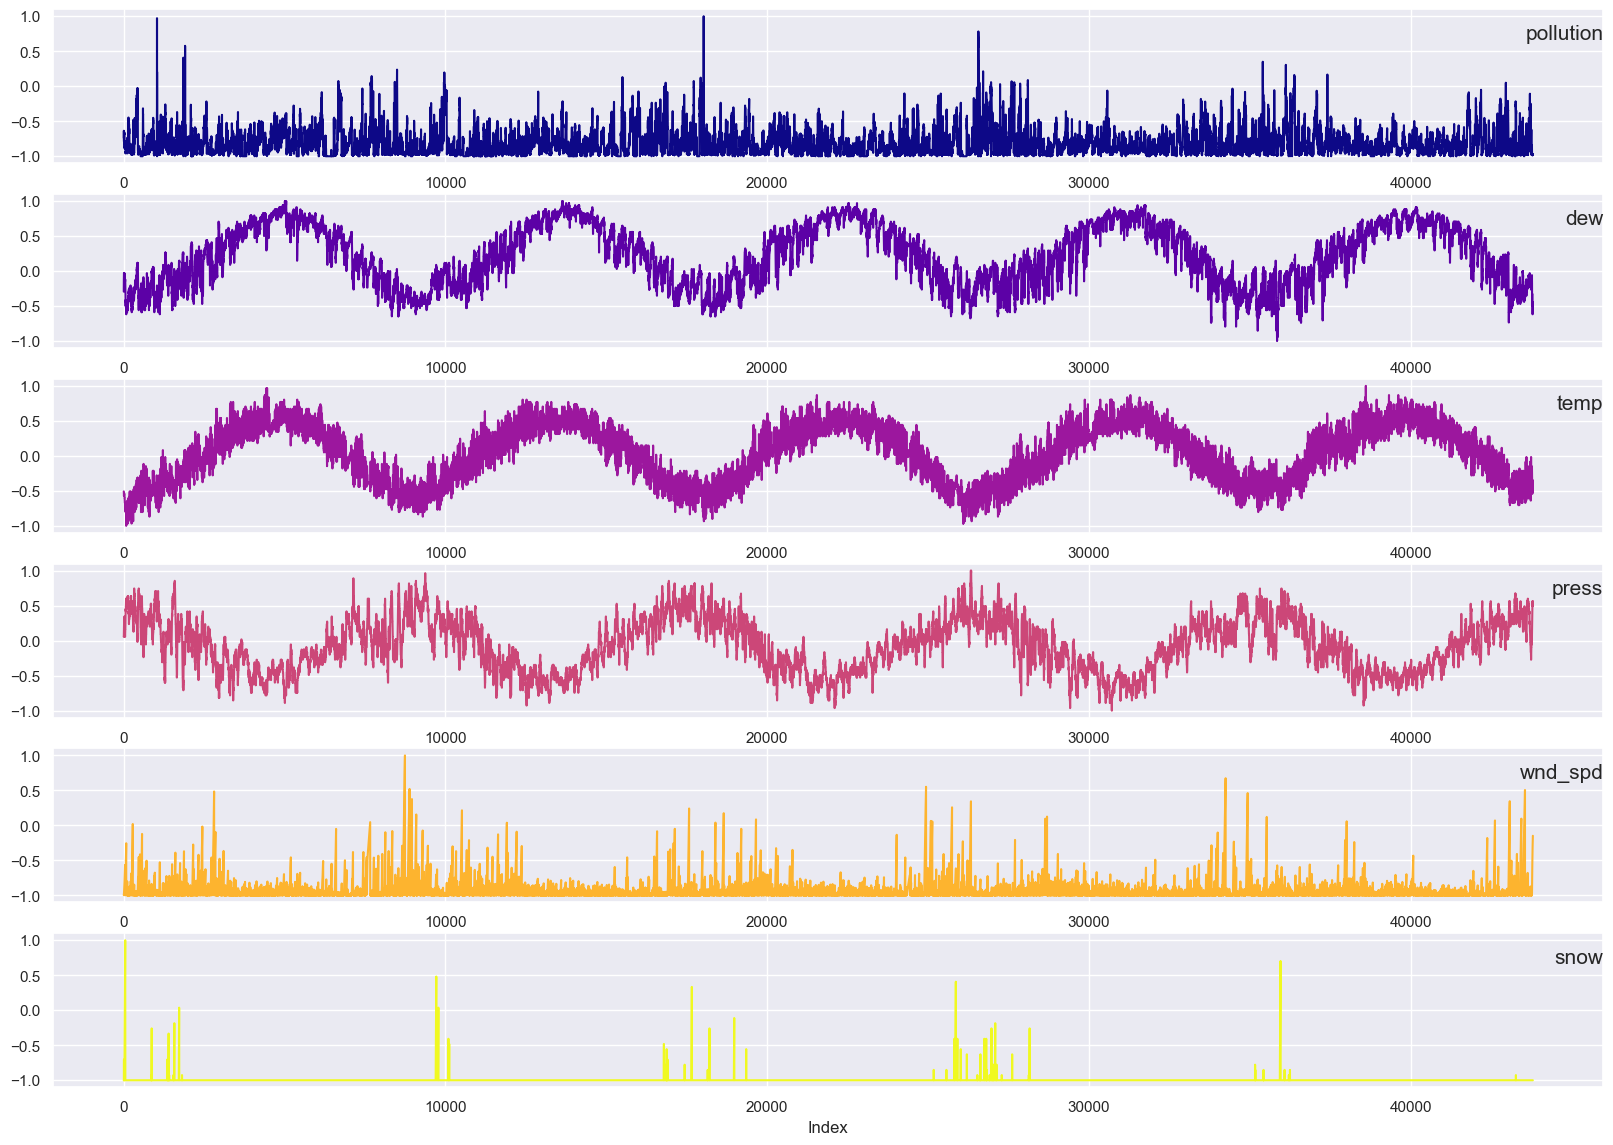

In [46]:
values = df_train_scaled.values
groups = [0, 1, 2, 3, 5, 6]  # 0 è pollution, 1 dew, 2 temp, 3 press, ecc.
i = 1

plt.figure(figsize=(20, 14))
for group in groups:
  plt.subplot(len(groups), 1, i)
  plt.plot(values[:, group], color=cm.plasma(group / len(groups)))
  plt.xlabel("Index")
  plt.title(df_train_scaled.columns[group], y=0.75, loc="right", fontsize=15)
  i += 1
plt.show()

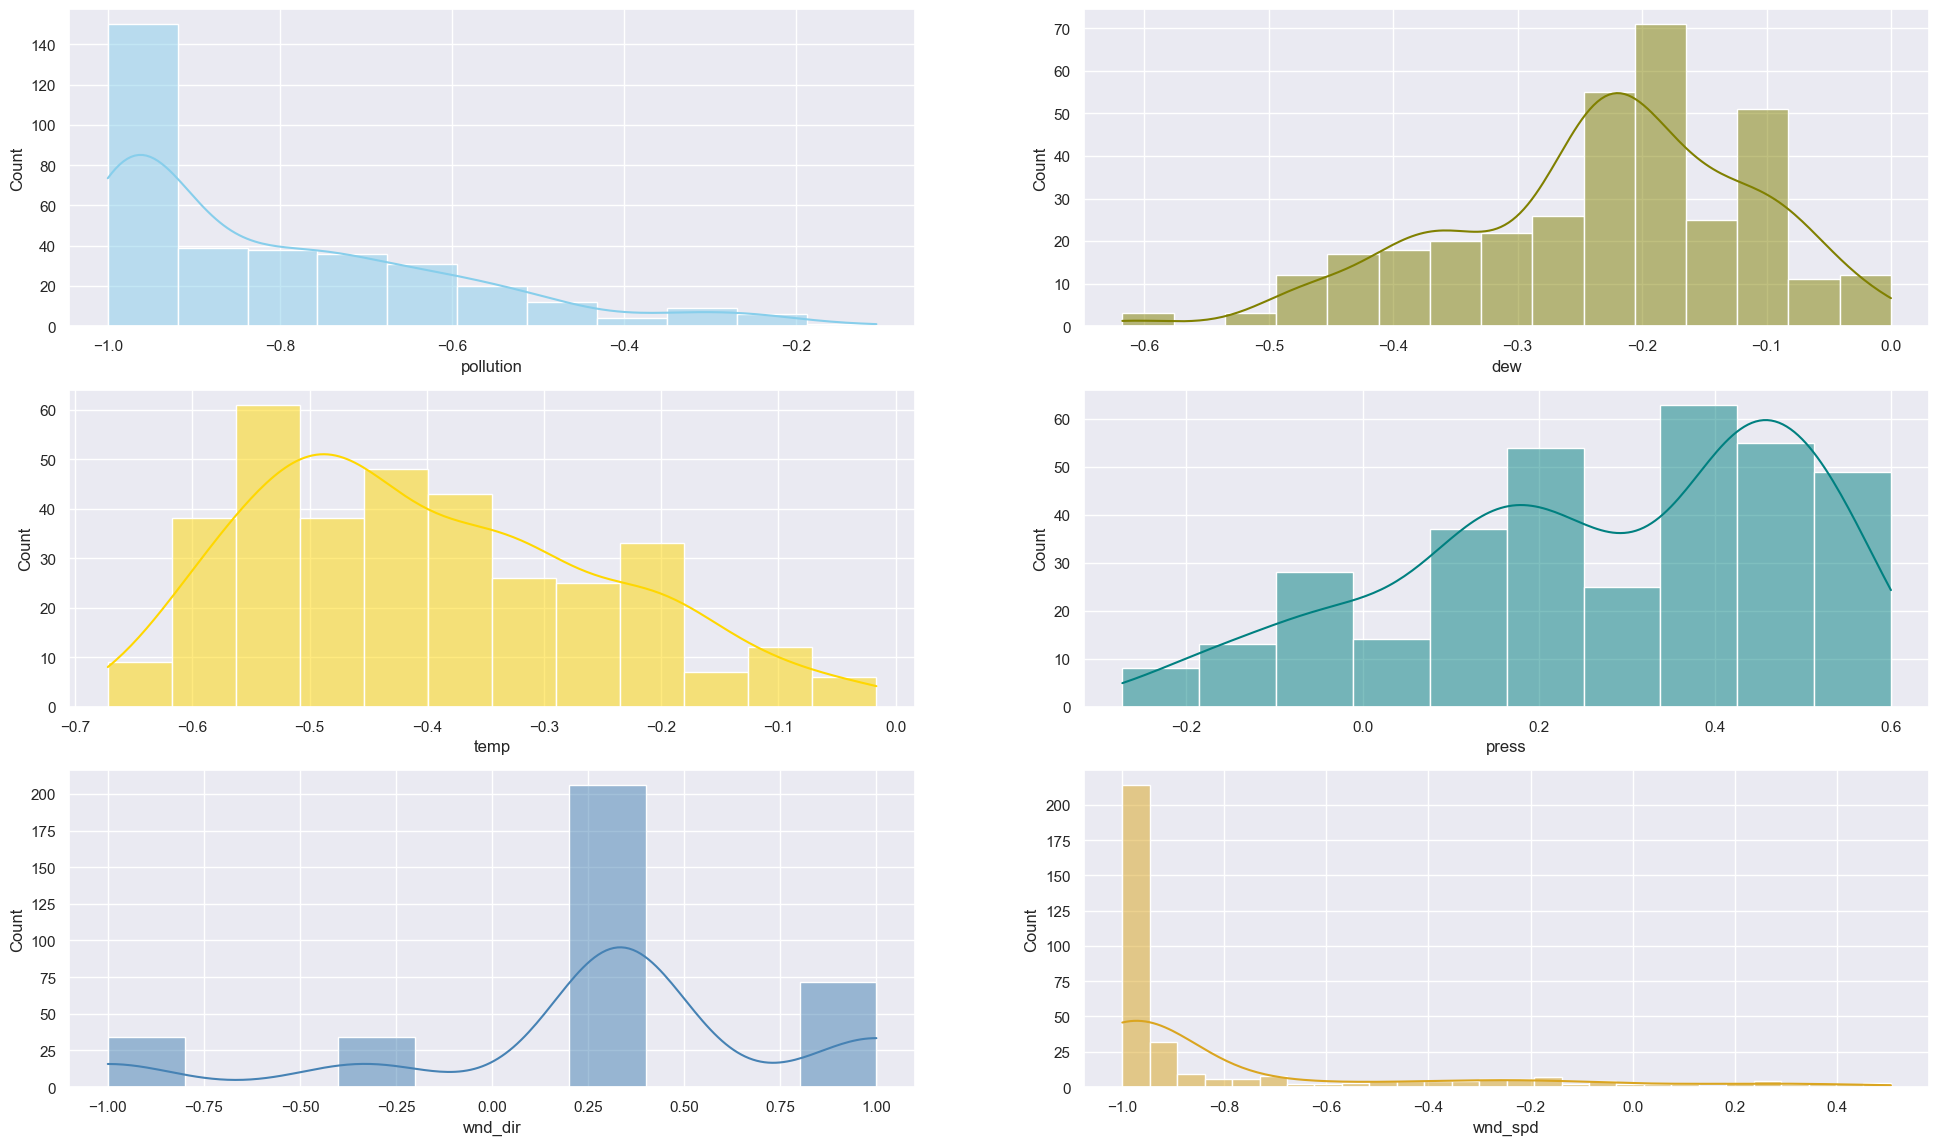

In [47]:
sns.set(style="darkgrid")

fig, axs = plt.subplots(3,2, figsize=(24,14))

sns.histplot(data=df_test_scaled, x="pollution", kde=True, color="skyblue", ax=axs[0, 0])
sns.histplot(data=df_test_scaled, x="dew", kde=True, color="olive", ax=axs[0, 1])
sns.histplot(data=df_test_scaled, x="temp", kde=True, color="gold", ax=axs[1, 0])
sns.histplot(data=df_test_scaled, x="press", kde=True, color="teal", ax=axs[1, 1])
sns.histplot(data=df_test_scaled, x="wnd_dir", kde=True, color="steelblue", ax=axs[2, 0])
sns.histplot(data=df_test_scaled, x="wnd_spd", kde=True, color="goldenrod", ax=axs[2, 1])

plt.show()

## Dataset with einops

In [48]:
import einops
from numpy.lib.stride_tricks import sliding_window_view
import torch
from torch.utils.data import DataLoader, Dataset

WINDOW_SIZE = 24  # 24 ore
STRIDE = 1  # passo di avanzamento (usa 24 per finestre disgiunte)


def make_windows(array_2d: np.ndarray, window_size: int = 24, stride: int = 1):
  """Converte un array (N, C) in tensori (NumWindows, C, T) tramite einops.

  array_2d: shape (N, C)
  ritorna:  shape (W, C, T)
  """
  # sliding_window_view su asse 0 produce shape (W, C, window_size)
  windows = sliding_window_view(array_2d, window_shape=window_size, axis=0)[
      ::stride
  ]
  # Riordiniamo esplicitamente in (Batch/Windows, Channels, Time) con einops
  tensor_bct = einops.rearrange(windows, "w c t -> w c t")
  return tensor_bct.astype(np.float32)


class Trajectory24hDataset(Dataset):

  def __init__(self, scaled_array_2d: np.ndarray, window_size: int = 24):
    # Gestione sicura se l'array è più corto di window_size (es. test set ridotto)
    if len(scaled_array_2d) < window_size:
      self.data = np.empty(
          (0, scaled_array_2d.shape[1], window_size), dtype=np.float32
      )
    else:
      self.data = make_windows(scaled_array_2d, window_size=window_size)

  def __len__(self):
    return len(self.data)

  def __getitem__(self, idx):
    x = torch.from_numpy(self.data[idx])  # shape: (C, 24)
    x0 = x[:, 0:1]  # condizione iniziale t=0: shape (C, 1)

    # Maschera stile CSDI: 1 = osservato/condizione (qui solo t=0), 0 = da generare
    cond_mask = torch.zeros_like(x, dtype=torch.bool)
    cond_mask[:, 0] = True

    return {
        "x": x,  # traiettoria completa 24h: (C, 24)
        "x0": x0,  # stato iniziale t=0: (C, 1)
        "cond_mask": cond_mask,  # maschera condizionamento: (C, 24)
    }


train_dataset = Trajectory24hDataset(train_scaled_values, window_size=WINDOW_SIZE)
test_dataset = Trajectory24hDataset(test_scaled_values, window_size=WINDOW_SIZE)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

batch = next(iter(train_loader))
print("x shape:        ", batch["x"].shape)  # (B, C, 24)
print("x0 shape:       ", batch["x0"].shape)  # (B, C, 1)
print("cond_mask shape:", batch["cond_mask"].shape)  # (B, C, 24)

x shape:         torch.Size([64, 8, 24])
x0 shape:        torch.Size([64, 8, 1])
cond_mask shape: torch.Size([64, 8, 24])


In [49]:
from diffusers import DDPMScheduler
import torch.nn as nn


class SinusoidalTimeEmb(nn.Module):

  def __init__(self, dim: int):
    super().__init__()
    self.dim = dim

  def forward(self, timesteps: torch.Tensor) -> torch.Tensor:
    half = self.dim // 2
    freqs = torch.exp(
        -torch.log(torch.tensor(10000.0, device=timesteps.device))
        * torch.arange(half, device=timesteps.device)
        / half
    )
    args = timesteps[:, None].float() * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)


class TrajectoryDenoiser1D(nn.Module):
  """Denoiser 1D su tensori (B, C, T) con embedding del timestep di diffusione."""

  def __init__(self, channels: int, hidden_dim: int = 128, time_dim: int = 64):
    super().__init__()
    self.time_mlp = nn.Sequential(
        SinusoidalTimeEmb(time_dim),
        nn.Linear(time_dim, hidden_dim),
        nn.SiLU(),
        nn.Linear(hidden_dim, hidden_dim),
    )
    # Concateniamo [x_noisy, x0_expanded] -> 2 * channels in ingresso
    self.net = nn.Sequential(
        nn.Conv1d(channels * 2, hidden_dim, kernel_size=3, padding=1),
        nn.SiLU(),
        nn.Conv1d(hidden_dim, hidden_dim, kernel_size=3, padding=1),
        nn.SiLU(),
        nn.Conv1d(hidden_dim, channels, kernel_size=3, padding=1),
    )

  def forward(
      self, x_t: torch.Tensor, x0: torch.Tensor, timestep: torch.Tensor
  ) -> torch.Tensor:
    # x_t: (B, C, T), x0: (B, C, 1) -> espandiamo x0 lungo T
    x0_exp = x0.expand_as(x_t)
    h = torch.cat([x_t, x0_exp], dim=1)  # (B, 2C, T)

    t_emb = self.time_mlp(timestep)[:, :, None]  # (B, hidden_dim, 1)
    out = self.net[0](h) + t_emb
    out = self.net[1](out)
    out = self.net[2](out) + t_emb
    out = self.net[3](out)
    return self.net[4](out)  # predizione del rumore eps: (B, C, T)


class Diffusion24hGenerator(nn.Module):

  def __init__(self, channels: int, num_train_timesteps: int = 200):
    super().__init__()
    self.model = TrajectoryDenoiser1D(channels=channels)
    self.scheduler = DDPMScheduler(
        num_train_timesteps=num_train_timesteps, beta_schedule="squaredcos_cap_v2"
    )

  def training_loss(self, x: torch.Tensor, x0: torch.Tensor) -> torch.Tensor:
    bsz = x.shape[0]
    device = x.device
    timesteps = torch.randint(
        0, self.scheduler.config.num_train_timesteps, (bsz,), device=device
    ).long()
    noise = torch.randn_like(x)

    noisy_x = self.scheduler.add_noise(x, noise, timesteps)
    # Manteniamo x0 noto al passo t=0
    noisy_x[:, :, 0:1] = x0

    pred_noise = self.model(noisy_x, x0, timesteps)
    # Loss su t=1..T-1 (o su tutto T)
    return nn.functional.mse_loss(pred_noise[:, :, 1:], noise[:, :, 1:])

  @torch.no_grad()
  def sample(
      self, x0: torch.Tensor, window_size: int = 24, num_steps: int = 50
  ) -> torch.Tensor:
    """Genera traiettorie complete (B, C, window_size) partendo da x0 (B, C, 1)."""
    device = x0.device
    bsz, channels, _ = x0.shape

    x_t = torch.randn((bsz, channels, window_size), device=device)
    x_t[:, :, 0:1] = x0

    self.scheduler.set_timesteps(num_steps, device=device)
    for t in self.scheduler.timesteps:
      t_batch = torch.full((bsz,), t, device=device, dtype=torch.long)
      pred_noise = self.model(x_t, x0, t_batch)
      x_t = self.scheduler.step(pred_noise, t, x_t).prev_sample
      # Re-impongo la condizione iniziale x0 a ogni passo di denoising
      x_t[:, :, 0:1] = x0

    return x_t

## Training loop

In [51]:
from pathlib import Path
import torch
from datetime import datetime

timestamp = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
filename = f"best_model_{timestamp}.pt"

CHECKPOINT_DIR = Path("parameters/pollution")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CKPT_PATH = CHECKPOINT_DIR / filename
LAST_CKPT_PATH = CHECKPOINT_DIR / "last_model.pt"


def save_checkpoint(
    path: Path,
    model: Diffusion24hGenerator,
    optimizer: torch.optim.Optimizer,
    epoch: int,
    train_loss: float,
    val_loss: float,
    feature_cols: list[str],
    scaler: MinMaxScaler,
):
  torch.save(
      {
          "epoch": epoch,
          "train_loss": train_loss,
          "val_loss": val_loss,
          "model_state_dict": model.state_dict(),
          "optimizer_state_dict": optimizer.state_dict(),
          "num_train_timesteps": model.scheduler.config.num_train_timesteps,
          "beta_schedule": model.scheduler.config.beta_schedule,
          "window_size": WINDOW_SIZE,
          "channels": len(feature_cols),
          "feature_cols": feature_cols,
          # Salviamo gli attributi del MinMaxScaler per inversione sicura
          "scaler_min_": scaler.min_,
          "scaler_scale_": scaler.scale_,
          "scaler_data_min_": scaler.data_min_,
          "scaler_data_max_": scaler.data_max_,
          "scaler_feature_range": scaler.feature_range,
      },
      path,
  )


@torch.no_grad()
def evaluate_loss(
    model: Diffusion24hGenerator, loader: DataLoader, device: torch.device
) -> float:
  model.eval()
  total_loss = 0.0
  num_batches = 0
  for batch in loader:
    x = batch["x"].to(device)
    x0 = batch["x0"].to(device)
    loss = model.training_loss(x, x0)
    total_loss += loss.item()
    num_batches += 1
  return total_loss / max(num_batches, 1)


def train_diffusion_model(
    model: Diffusion24hGenerator,
    train_loader: DataLoader,
    val_loader: DataLoader,
    feature_cols: list[str],
    scaler: MinMaxScaler,
    epochs: int = 30,
    lr: float = 1e-3,
    device: torch.device | None = None,
):
  if device is None:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

  model = model.to(device)
  optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
  scheduler_lr = torch.optim.lr_scheduler.CosineAnnealingLR(
      optimizer, T_max=epochs, eta_min=lr * 0.05
  )

  best_val_loss = float("inf")
  history = {"train_loss": [], "val_loss": []}

  for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    num_batches = 0

    for batch in train_loader:
      x = batch["x"].to(device)  # (B, C, 24)
      x0 = batch["x0"].to(device)  # (B, C, 1)

      optimizer.zero_grad()
      loss = model.training_loss(x, x0)
      loss.backward()
      torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
      optimizer.step()

      running_loss += loss.item()
      num_batches += 1

    scheduler_lr.step()
    train_loss = running_loss / max(num_batches, 1)
    val_loss = (
        evaluate_loss(model, val_loader, device)
        if len(val_loader) > 0
        else train_loss
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    save_checkpoint(
        LAST_CKPT_PATH,
        model,
        optimizer,
        epoch,
        train_loss,
        val_loss,
        feature_cols,
        scaler,
    )

    if val_loss < best_val_loss:
      best_val_loss = val_loss
      save_checkpoint(
          BEST_CKPT_PATH,
          model,
          optimizer,
          epoch,
          train_loss,
          val_loss,
          feature_cols,
          scaler,
      )
      marker = " <-- best"
    else:
      marker = ""

    print(
        f"Epoch {epoch:03d}/{epochs:03d} | "
        f"Train Loss: {train_loss:.5f} | "
        f"Val Loss: {val_loss:.5f}{marker}"
    )

  return history


# Esempio di avvio training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
generator = Diffusion24hGenerator(
    channels=len(FEATURE_COLS), num_train_timesteps=200
)
history = train_diffusion_model(
    model=generator,
    train_loader=train_loader,
    val_loader=test_loader,
    feature_cols=FEATURE_COLS,
    scaler=scaler,
    epochs=20,
    lr=1e-3,
    device=device,
)

Epoch 001/020 | Train Loss: 0.16735 | Val Loss: 0.11226 <-- best
Epoch 002/020 | Train Loss: 0.10949 | Val Loss: 0.08637 <-- best
Epoch 003/020 | Train Loss: 0.10195 | Val Loss: 0.09272
Epoch 004/020 | Train Loss: 0.09613 | Val Loss: 0.11115
Epoch 005/020 | Train Loss: 0.09330 | Val Loss: 0.08426 <-- best
Epoch 006/020 | Train Loss: 0.08984 | Val Loss: 0.08963
Epoch 007/020 | Train Loss: 0.08725 | Val Loss: 0.08326 <-- best
Epoch 008/020 | Train Loss: 0.08707 | Val Loss: 0.07743 <-- best
Epoch 009/020 | Train Loss: 0.08516 | Val Loss: 0.08061
Epoch 010/020 | Train Loss: 0.08458 | Val Loss: 0.07839
Epoch 011/020 | Train Loss: 0.08432 | Val Loss: 0.08698
Epoch 012/020 | Train Loss: 0.08244 | Val Loss: 0.07241 <-- best
Epoch 013/020 | Train Loss: 0.08091 | Val Loss: 0.09433
Epoch 014/020 | Train Loss: 0.08039 | Val Loss: 0.08647
Epoch 015/020 | Train Loss: 0.07935 | Val Loss: 0.06426 <-- best
Epoch 016/020 | Train Loss: 0.07980 | Val Loss: 0.08188
Epoch 017/020 | Train Loss: 0.07862 | Val

## Generate samples from the trained model

Generate 500 traiettorie da 24h (50 x0 x 10 campioni).
File salvati in: C:\Università\Tesi Magistrale\thesis_project\generated_trajectories


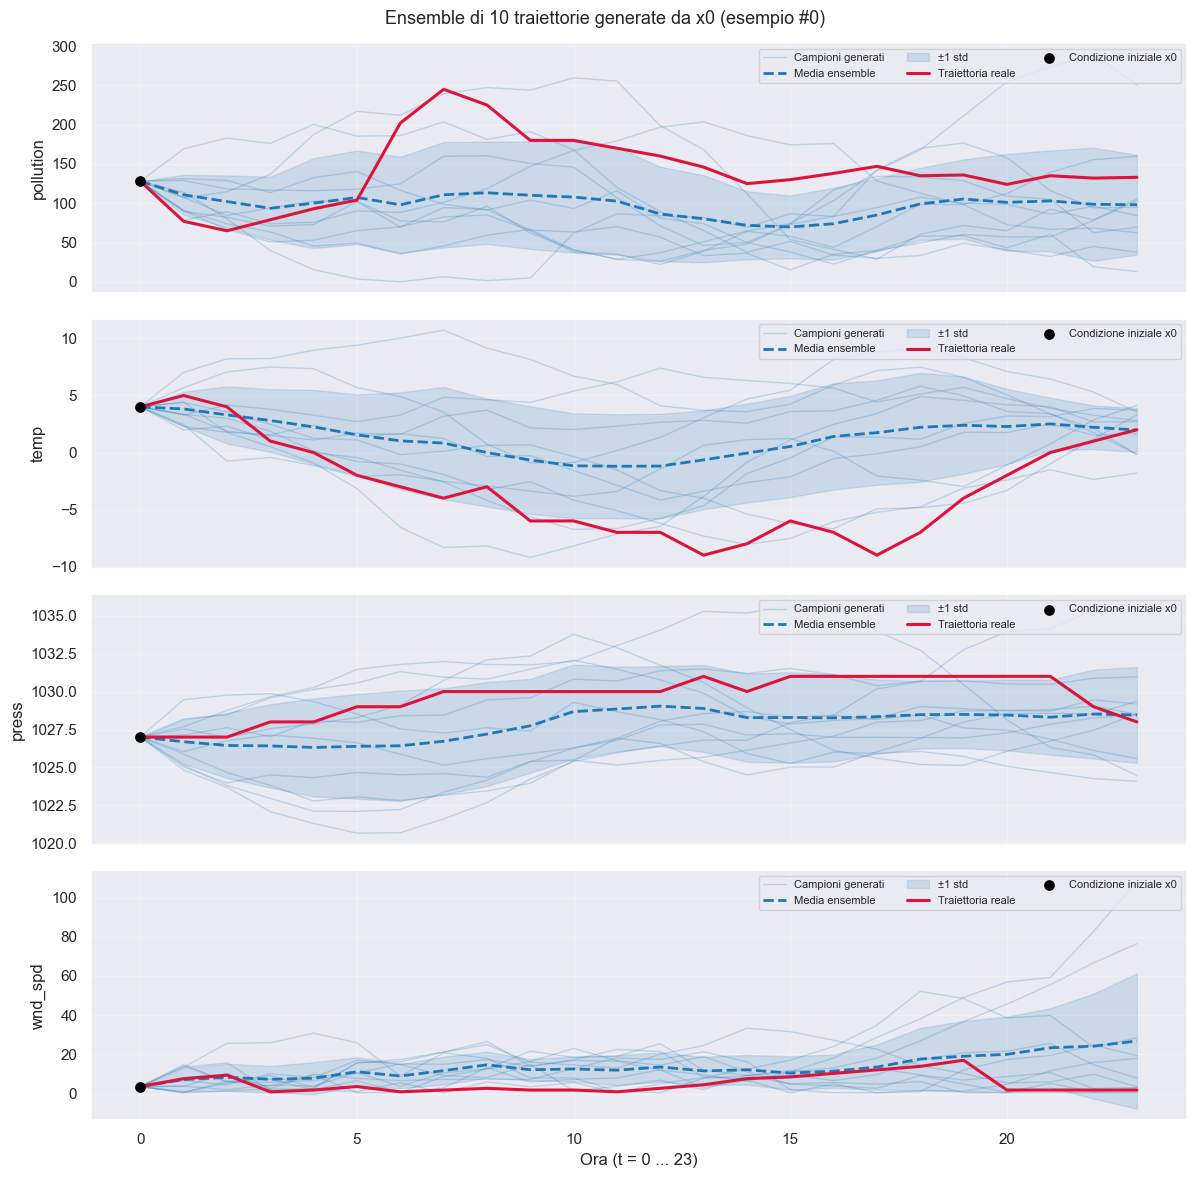

In [52]:
from pathlib import Path
from diffusers import DDPMScheduler
import einops
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import torch

# ==============================================================================
# 1. FUNZIONI DI CARICAMENTO E GENERAZIONE
# ==============================================================================


def rebuild_scaler_from_ckpt(ckpt: dict) -> MinMaxScaler:
  sc = MinMaxScaler(feature_range=ckpt["scaler_feature_range"])
  sc.min_ = ckpt["scaler_min_"]
  sc.scale_ = ckpt["scaler_scale_"]
  sc.data_min_ = ckpt["scaler_data_min_"]
  sc.data_max_ = ckpt["scaler_data_max_"]
  sc.n_features_in_ = len(sc.min_)
  return sc


def load_trained_generator(
    ckpt_path: Path, device: torch.device | None = None
):
  if device is None:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

  ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
  model = Diffusion24hGenerator(
      channels=ckpt["channels"],
      num_train_timesteps=ckpt["num_train_timesteps"],
  )
  model.scheduler = DDPMScheduler(
      num_train_timesteps=ckpt["num_train_timesteps"],
      beta_schedule=ckpt["beta_schedule"],
  )
  model.load_state_dict(ckpt["model_state_dict"])
  model.to(device)
  model.eval()

  scaler_loaded = rebuild_scaler_from_ckpt(ckpt)
  return model, scaler_loaded, ckpt


def trajectories_to_original_scale(
    trajectories_bct: torch.Tensor, scaler_obj: MinMaxScaler
) -> np.ndarray:
  """Converte un tensore (N, C, T) in [-1, 1] in un array (N, T, C) nella scala originale."""
  arr_ntc = einops.rearrange(trajectories_bct.detach().cpu().numpy(), "n c t -> n t c")
  n_traj, t_steps, n_feat = arr_ntc.shape
  inv_2d = scaler_obj.inverse_transform(arr_ntc.reshape(-1, n_feat))
  return inv_2d.reshape(n_traj, t_steps, n_feat)


@torch.no_grad()
def generate_from_initial_conditions(
    model: Diffusion24hGenerator,
    x0_batch: torch.Tensor,
    scaler_obj: MinMaxScaler,
    num_samples_per_x0: int = 1,
    window_size: int = 24,
    num_steps: int = 50,
    batch_size: int = 128,
    device: torch.device | None = None,
):
  """Genera traiettorie condizionate a x0_batch (M, C, 1) elaborando a mini-batch."""
  if device is None:
    device = next(model.parameters()).device

  x0_rep = einops.repeat(x0_batch, "m c 1 -> (m k) c 1", k=num_samples_per_x0)
  all_scaled = []

  for start in range(0, len(x0_rep), batch_size):
    x0_chunk = x0_rep[start : start + batch_size].to(device)
    gen_chunk = model.sample(
        x0_chunk, window_size=window_size, num_steps=num_steps
    )
    all_scaled.append(gen_chunk.cpu())

  scaled_bct = torch.cat(all_scaled, dim=0)  # (M*K, C, T)
  original_ntc = trajectories_to_original_scale(scaled_bct, scaler_obj)  # (M*K, T, C)
  return scaled_bct, original_ntc


# ==============================================================================
# 2. ESECUZIONE GENERAZIONE & SALVATAGGIO TRAIETTORIE
# ==============================================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
loaded_model, loaded_scaler, ckpt_info = load_trained_generator(
    BEST_CKPT_PATH, device=device
)
feature_cols = ckpt_info["feature_cols"]
window_size = ckpt_info["window_size"]

# Estraiamo le finestre reali del test set come riferimento
real_test_bct = torch.from_numpy(test_dataset.data)  # (N_test, C, 24)
real_test_ntc = trajectories_to_original_scale(real_test_bct, loaded_scaler)

# Selezioniamo M condizioni iniziali dal test set e generiamo K=10 traiettorie ciascuna
N_COND = min(50, len(real_test_bct))
K_SAMPLES = 10
x0_conditions = real_test_bct[:N_COND, :, 0:1]  # (N_COND, C, 1)

gen_scaled_bct, gen_orig_ntc = generate_from_initial_conditions(
    model=loaded_model,
    x0_batch=x0_conditions,
    scaler_obj=loaded_scaler,
    num_samples_per_x0=K_SAMPLES,
    window_size=window_size,
    num_steps=50,
    device=device,
)

# Salvataggio su disco (formato compatto .npz + .csv tabellare pronto per tool esterni)
OUTPUT_DIR = Path("generated_trajectories")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    OUTPUT_DIR / "synthetic_24h.npz",
    gen_orig_ntc=gen_orig_ntc,
    gen_scaled_bct=gen_scaled_bct.numpy(),
    real_ref_ntc=real_test_ntc[:N_COND],
    feature_cols=np.array(feature_cols),
)

# Esportazione CSV (ogni traiettoria identificata da trajectory_id e hour 0..23)
n_tot, t_len, n_ch = gen_orig_ntc.shape
df_export = pd.DataFrame(gen_orig_ntc.reshape(-1, n_ch), columns=feature_cols)
df_export.insert(0, "hour", np.tile(np.arange(t_len), n_tot))
df_export.insert(0, "trajectory_id", np.repeat(np.arange(n_tot), t_len))
df_export.to_csv(OUTPUT_DIR / "synthetic_24h.csv", index=False)

print(
    f"Generate {gen_orig_ntc.shape[0]} traiettorie da {t_len}h ({N_COND} x0 x"
    f" {K_SAMPLES} campioni)."
)
print(f"File salvati in: {OUTPUT_DIR.resolve()}")

# ==============================================================================
# 3. VISUALIZZAZIONE: ENSEMBLE GENERATO DA UNA SINGOLA CONDIZIONE INIZIALE x0
# ==============================================================================

# Riorganizziamo in (N_COND, K_SAMPLES, T, C) per ispezionare l'ensemble di un singolo x0
ensemble_nk_tc = einops.rearrange(
    gen_orig_ntc, "(m k) t c -> m k t c", m=N_COND, k=K_SAMPLES
)

idx_example = 0  # scegli l'indice della condizione iniziale da ispezionare
vars_to_plot = ["pollution", "temp", "press", "wnd_spd"]
var_indices = [feature_cols.index(v) for v in vars_to_plot if v in feature_cols]

fig, axes = plt.subplots(
    len(var_indices), 1, figsize=(12, 3 * len(var_indices)), sharex=True
)
hours = np.arange(window_size)

for ax, c_idx in zip(axes, var_indices):
  var_name = feature_cols[c_idx]
  real_curve = real_test_ntc[idx_example, :, c_idx]
  sim_curves = ensemble_nk_tc[idx_example, :, :, c_idx]  # (K_SAMPLES, 24)

  mean_curve = sim_curves.mean(axis=0)
  std_curve = sim_curves.std(axis=0)

  # Singole traiettorie campionate
  for k in range(K_SAMPLES):
    ax.plot(
        hours,
        sim_curves[k],
        color="tab:blue",
        alpha=0.22,
        linewidth=1.0,
        label="Campioni generati" if k == 0 else "",
    )

  # Media e banda +/- 1 std dell'ensemble
  ax.plot(
      hours,
      mean_curve,
      color="tab:blue",
      linestyle="--",
      linewidth=2.0,
      label="Media ensemble",
  )
  ax.fill_between(
      hours,
      mean_curve - std_curve,
      mean_curve + std_curve,
      color="tab:blue",
      alpha=0.15,
      label="±1 std",
  )

  # Traiettoria reale osservata a partire dallo stesso x0
  ax.plot(
      hours,
      real_curve,
      color="crimson",
      linewidth=2.2,
      label="Traiettoria reale",
  )
  ax.scatter(
      [0],
      [real_curve[0]],
      color="black",
      zorder=5,
      s=45,
      label="Condizione iniziale x0",
  )

  ax.set_ylabel(var_name)
  ax.grid(True, alpha=0.3)
  ax.legend(loc="upper right", ncol=3, fontsize=8)

axes[-1].set_xlabel("Ora (t = 0 ... 23)")
fig.suptitle(
    f"Ensemble di {K_SAMPLES} traiettorie generate da x0 (esempio #{idx_example})",
    fontsize=13,
)
plt.tight_layout()
plt.show()

## Analysis of the generated trajectories

=== CONFRONTO STATISTICO MARGINALE (SCALA ORIGINALE) ===
  Feature  Real Mean  Gen Mean  Real Std  Gen Std  Wasserstein 1D
pollution     98.002   124.201    99.456   83.846          30.208
      dew    -13.543   -11.638     3.782    4.291           1.908
     temp     -0.555     0.247     4.597    4.924           0.974
    press   1025.729  1026.082     6.007    3.778           2.075
  wnd_dir      1.921     1.704     0.835    0.838           0.357
  wnd_spd     59.499    17.333   106.928   21.445          44.828
     snow      0.000     0.125     0.000    0.156           0.125
     rain      0.000     0.076     0.000    0.134           0.076

=== MONITORAGGIO PROPRIETÀ TEMPORALE (pollution > 160.0 per >= 3h) ===
Tasso soddisfazione Reale:    44.9% | Robustezza media: 2.44
Tasso soddisfazione Generato: 60.4% | Robustezza media: 31.14

=== TEST DISCRIMINATIVO (REAL VS SYNTHETIC) ===
ROC-AUC (5-fold CV): 1.000 ± 0.000 (0.50 = indistinguibile, 1.00 = facilmente separabile)


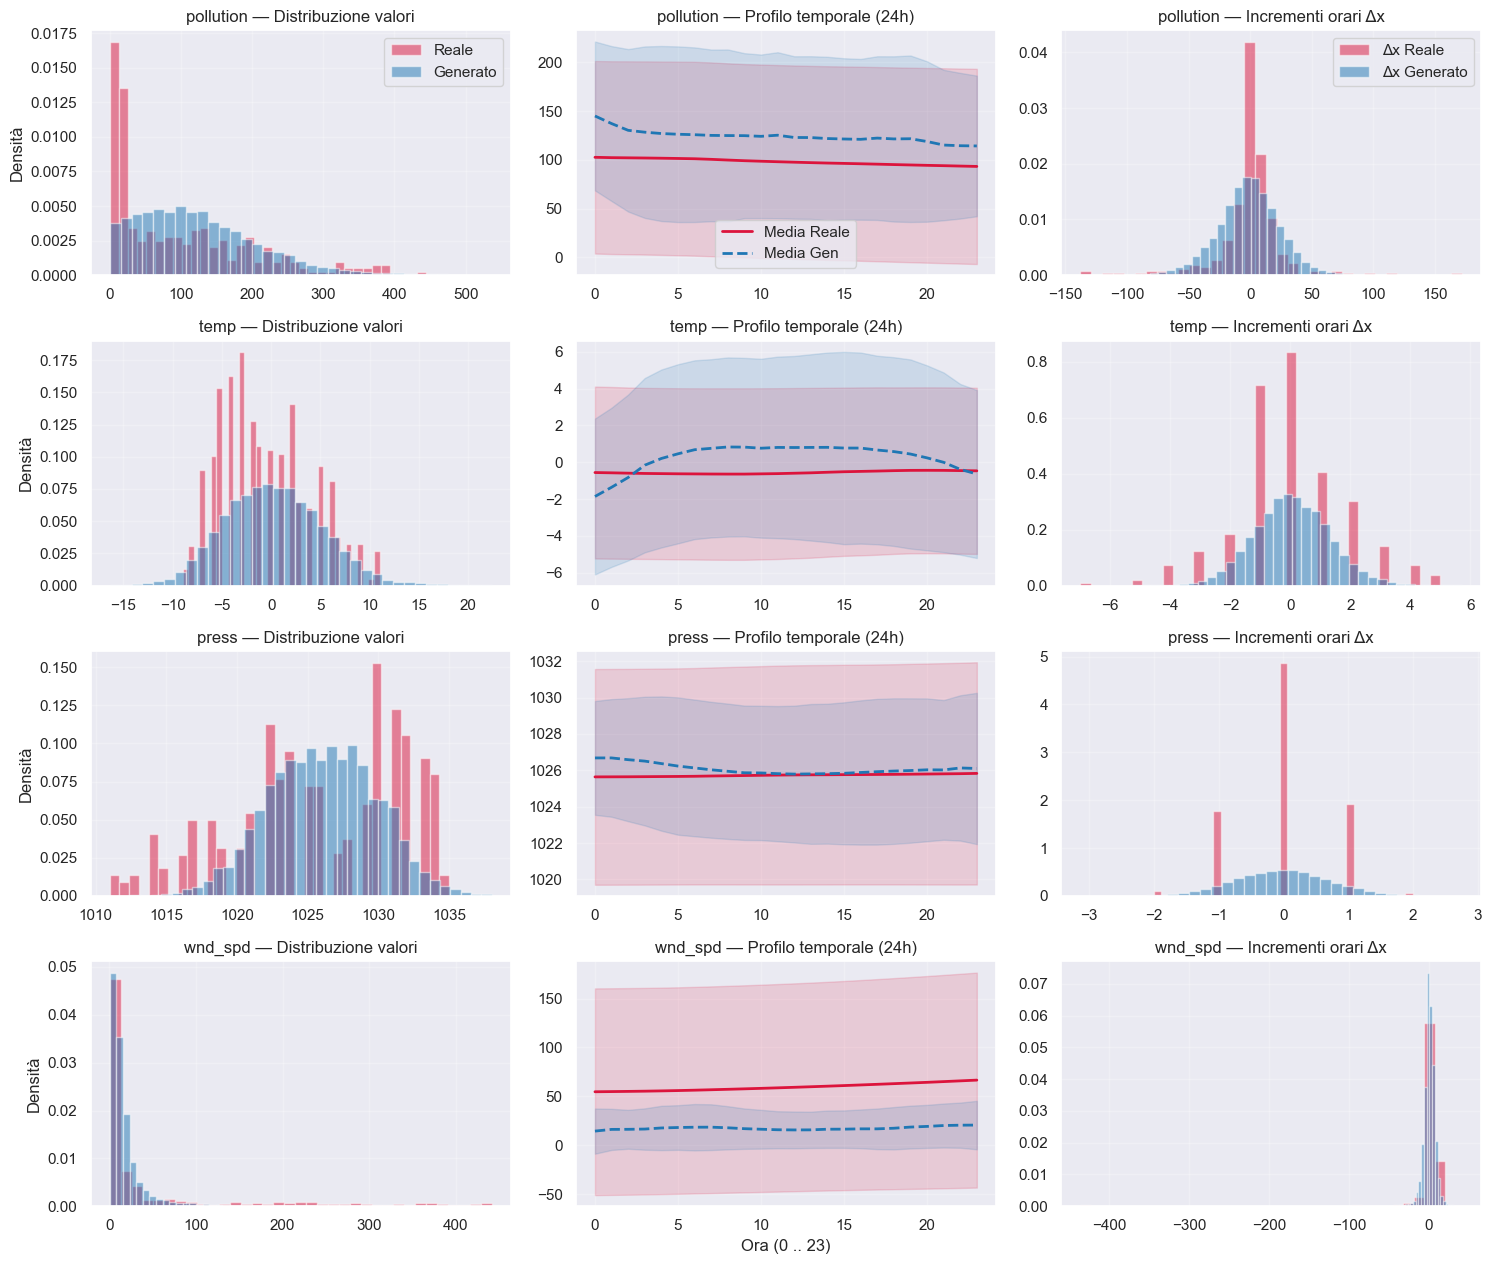

In [53]:
from scipy.stats import wasserstein_distance
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Carichiamo i dati (funziona sia in continuazione sia in una nuova sessione)
data_npz = np.load(Path("generated_trajectories/synthetic_24h.npz"))
gen_ntc = data_npz["gen_orig_ntc"]  # (N_gen, 24, C)
real_ntc = trajectories_to_original_scale(
    torch.from_numpy(test_dataset.data), loaded_scaler
)  # (N_real, 24, C)
cols = list(data_npz["feature_cols"])

# ==============================================================================
# 1. TABELLA STATISTICA & DISTANZA DI WASSERSTEIN (REALE VS GENERATO)
# ==============================================================================

stats_rows = []
for c_idx, col_name in enumerate(cols):
  r_vals = real_ntc[:, :, c_idx].ravel()
  g_vals = gen_ntc[:, :, c_idx].ravel()
  w_dist = wasserstein_distance(r_vals, g_vals)
  stats_rows.append({
      "Feature": col_name,
      "Real Mean": np.mean(r_vals),
      "Gen Mean": np.mean(g_vals),
      "Real Std": np.std(r_vals),
      "Gen Std": np.std(g_vals),
      "Wasserstein 1D": w_dist,
  })

df_stats = pd.DataFrame(stats_rows)
print("=== CONFRONTO STATISTICO MARGINALE (SCALA ORIGINALE) ===")
print(df_stats.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

# ==============================================================================
# 2. MONITORAGGIO PROPRIETÀ TEMPORALE (ROBUSTEZZA QUANTITATIVA STILE STL)
# ==============================================================================
# Proprietà esempio: "Esiste un intervallo in cui pollution > soglia per almeno 3 ore consecutive"
# F_[0, 21] ( G_[0, 2] (pollution > threshold) )

poll_idx = cols.index("pollution")
threshold = np.percentile(
    real_ntc[:, :, poll_idx], 75
)  # soglia critica: 75° percentile reale


def stl_persistence_robustness(
    traj_ntc: np.ndarray, var_idx: int, thresh: float, duration: int = 3
) -> np.ndarray:
  """Calcola la robustezza quantitativa per ogni traiettoria (N,):

  rho > 0 <=> proprietà soddisfatta; rho <= 0 <=> violata.
  """
  signal = traj_ntc[:, :, var_idx] - thresh  # (N, 24)
  # Finestra scorrevole di ampiezza `duration`: min interno (operatore Globally), max esterno (Eventually)
  n_traj, t_len = signal.shape
  g_scores = np.stack(
      [
          signal[:, t : t + duration].min(axis=1)
          for t in range(t_len - duration + 1)
      ],
      axis=1,
  )
  return g_scores.max(axis=1)


rho_real = stl_persistence_robustness(real_ntc, poll_idx, threshold, duration=3)
rho_gen = stl_persistence_robustness(gen_ntc, poll_idx, threshold, duration=3)

print(
    f"\n=== MONITORAGGIO PROPRIETÀ TEMPORALE (pollution > {threshold:.1f} per"
    " >= 3h) ==="
)
print(
    f"Tasso soddisfazione Reale:    {(rho_real > 0).mean()*100:.1f}% |"
    f" Robustezza media: {rho_real.mean():.2f}"
)
print(
    f"Tasso soddisfazione Generato: {(rho_gen > 0).mean()*100:.1f}% |"
    f" Robustezza media: {rho_gen.mean():.2f}"
)

# ==============================================================================
# 3. TEST DISCRIMINATIVO (CLASSIFICATORE REAL VS SYNTHETIC)
# ==============================================================================


def extract_trajectory_features(arr_ntc: np.ndarray) -> np.ndarray:
  """Estrae feature sintetiche per traiettoria: media, std, min, max, media |delta_t|."""
  mean_f = arr_ntc.mean(axis=1)
  std_f = arr_ntc.std(axis=1)
  min_f = arr_ntc.min(axis=1)
  max_f = arr_ntc.max(axis=1)
  diff_f = np.abs(np.diff(arr_ntc, axis=1)).mean(axis=1)
  return np.concatenate([mean_f, std_f, min_f, max_f, diff_f], axis=1)


n_balanced = min(len(real_ntc), len(gen_ntc))
rng = np.random.default_rng(42)
idx_r = rng.choice(len(real_ntc), size=n_balanced, replace=False)
idx_g = rng.choice(len(gen_ntc), size=n_balanced, replace=False)

X_disc = np.vstack([
    extract_trajectory_features(real_ntc[idx_r]),
    extract_trajectory_features(gen_ntc[idx_g]),
])
y_disc = np.concatenate([np.ones(n_balanced), np.zeros(n_balanced)])

clf = RandomForestClassifier(n_estimators=100, random_state=42)
auc_scores = cross_val_score(clf, X_disc, y_disc, cv=5, scoring="roc_auc")
print("\n=== TEST DISCRIMINATIVO (REAL VS SYNTHETIC) ===")
print(
    f"ROC-AUC (5-fold CV): {auc_scores.mean():.3f} ± {auc_scores.std():.3f} "
    "(0.50 = indistinguibile, 1.00 = facilmente separabile)"
)

# ==============================================================================
# 4. DATA VISUALIZATION DIAGNOSTICA (DISTRIBUZIONI, PROFILO 24H, DINAMICA DELTA)
# ==============================================================================

selected_vars = ["pollution", "temp", "press", "wnd_spd"]
sel_indices = [cols.index(v) for v in selected_vars if v in cols]

fig, axes = plt.subplots(
    len(sel_indices), 3, figsize=(15, 3.2 * len(sel_indices))
)
hours = np.arange(real_ntc.shape[1])

for row, c_idx in enumerate(sel_indices):
  vname = cols[c_idx]
  r_mat = real_ntc[:, :, c_idx]
  g_mat = gen_ntc[:, :, c_idx]

  # Colonna 1: Distribuzione marginale dei valori
  ax_dist = axes[row, 0]
  ax_dist.hist(
      r_mat.ravel(),
      bins=35,
      density=True,
      alpha=0.5,
      color="crimson",
      label="Reale",
  )
  ax_dist.hist(
      g_mat.ravel(),
      bins=35,
      density=True,
      alpha=0.5,
      color="tab:blue",
      label="Generato",
  )
  ax_dist.set_title(f"{vname} — Distribuzione valori")
  ax_dist.set_ylabel("Densità")
  ax_dist.grid(True, alpha=0.25)
  if row == 0:
    ax_dist.legend()

  # Colonna 2: Profilo medio e banda +/- 1 std lungo le 24 ore
  ax_prof = axes[row, 1]
  ax_prof.plot(
      hours, r_mat.mean(axis=0), color="crimson", lw=2, label="Media Reale"
  )
  ax_prof.fill_between(
      hours,
      r_mat.mean(axis=0) - r_mat.std(axis=0),
      r_mat.mean(axis=0) + r_mat.std(axis=0),
      color="crimson",
      alpha=0.15,
  )
  ax_prof.plot(
      hours,
      g_mat.mean(axis=0),
      color="tab:blue",
      lw=2,
      linestyle="--",
      label="Media Gen",
  )
  ax_prof.fill_between(
      hours,
      g_mat.mean(axis=0) - g_mat.std(axis=0),
      g_mat.mean(axis=0) + g_mat.std(axis=0),
      color="tab:blue",
      alpha=0.15,
  )
  ax_prof.set_title(f"{vname} — Profilo temporale (24h)")
  ax_prof.grid(True, alpha=0.25)
  if row == 0:
    ax_prof.legend()

  # Colonna 3: Distribuzione delle variazioni orarie (delta_x = x[t+1] - x[t])
  ax_diff = axes[row, 2]
  r_diff = np.diff(r_mat, axis=1).ravel()
  g_diff = np.diff(g_mat, axis=1).ravel()
  ax_diff.hist(
      r_diff,
      bins=35,
      density=True,
      alpha=0.5,
      color="crimson",
      label="Δx Reale",
  )
  ax_diff.hist(
      g_diff,
      bins=35,
      density=True,
      alpha=0.5,
      color="tab:blue",
      label="Δx Generato",
  )
  ax_diff.set_title(f"{vname} — Incrementi orari Δx")
  ax_diff.grid(True, alpha=0.25)
  if row == 0:
    ax_diff.legend()

axes[-1, 1].set_xlabel("Ora (0 .. 23)")
plt.tight_layout()
plt.show()